# Fase 1 — Análisis exploratorio de datos (EDA)

**Objetivo:** entender qué información tenemos, qué problemas de calidad hay y qué patrones
se asocian al abandono de clientes (*churn*), antes de construir cualquier modelo.

**Importante:** en esta fase **no modificamos** el dataset original. Solo observamos y anotamos
las decisiones de limpieza que se aplicarán en la Fase 2 (dentro de un Pipeline).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RUTA_DATOS = Path("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
RUTA_FIGURAS = Path("../results/figuras")
RUTA_FIGURAS.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(RUTA_DATOS)
print(f"Filas: {df.shape[0]}  |  Columnas: {df.shape[1]}")
df.head()

Filas: 7043  |  Columnas: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Estructura y calidad de los datos

In [2]:
# Tipos de cada columna
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

In [3]:
# Valores nulos y duplicados
print("Nulos por columna (total):", df.isna().sum().sum())
print("customerID duplicados:", df["customerID"].duplicated().sum())

Nulos por columna (total): 0
customerID duplicados: 0


In [4]:
# TotalCharges debería ser numérica pero viene como texto (object).
# Probamos convertirla para encontrar valores que no son números.
total_num = pd.to_numeric(df["TotalCharges"], errors="coerce")
filas_problema = df[total_num.isna()]
print(f"Filas con TotalCharges no numérico: {len(filas_problema)}")
filas_problema[["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

Filas con TotalCharges no numérico: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


**Hallazgo de calidad:** hay **11 filas** donde `TotalCharges` es un espacio vacío (`" "`).
Pandas no lo detecta como nulo porque es texto, por eso `isna()` decía 0.
Todas tienen `tenure = 0`: son clientes **recién dados de alta** que todavía no pagaron nada.

**Decisión para la Fase 2:** convertir `TotalCharges` a número y rellenar esas 11 filas con **0**
(tiene sentido de negocio: aún no se les cobró). Alternativa: eliminarlas (son el 0,16 % de los datos).

In [5]:
# Columnas que NO deben usarse como features
print("customerID: valores únicos =", df["customerID"].nunique(), "de", len(df))

customerID: valores únicos = 7043 de 7043


**`customerID`** es un identificador único por cliente: no aporta información para predecir y un
modelo podría "memorizarlo". **Se elimina de las features.**

Además, varias columnas tienen la categoría `"No internet service"` / `"No phone service"`,
que repite información de `InternetService` y `PhoneService`. No es un error, pero conviene saberlo.

## 2. Variable objetivo: ¿está desbalanceada?

       clientes  proporción
Churn                      
No         5174       0.735
Yes        1869       0.265


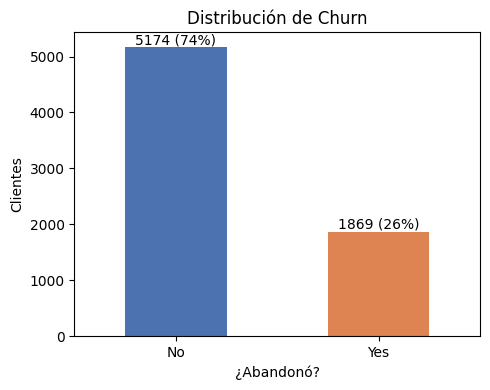

In [6]:
conteo = df["Churn"].value_counts()
proporcion = df["Churn"].value_counts(normalize=True).round(3)
print(pd.DataFrame({"clientes": conteo, "proporción": proporcion}))

fig, ax = plt.subplots(figsize=(5, 4))
conteo.plot(kind="bar", ax=ax, color=["#4C72B0", "#DD8452"])
ax.set_title("Distribución de Churn")
ax.set_xlabel("¿Abandonó?")
ax.set_ylabel("Clientes")
ax.tick_params(axis="x", rotation=0)
for i, v in enumerate(conteo):
    ax.text(i, v + 50, f"{v} ({proporcion.iloc[i]:.0%})", ha="center")
plt.tight_layout()
plt.savefig(RUTA_FIGURAS / "01_distribucion_churn.png", dpi=120)
plt.show()

**Hallazgo:** solo el **26,5 %** de los clientes abandona. El dataset está **desbalanceado**.

Consecuencia: un modelo "tonto" que diga siempre *"no abandona"* tendría **73,5 % de accuracy**
sin detectar a nadie. Por eso la accuracy **no** sirve como métrica principal: usaremos recall,
precision, F1, ROC-AUC y, sobre todo, el **costo en USD** (FN = 120, FP = 15).

## 3. ¿Qué variables se asocian al abandono?

In [7]:
df["churn_num"] = (df["Churn"] == "Yes").astype(int)  # columna auxiliar solo para el análisis

def tasa_churn(columna):
    return (df.groupby(columna)["churn_num"].mean()
              .sort_values(ascending=False).round(3))

for col in ["Contract", "InternetService", "PaymentMethod", "TechSupport",
            "OnlineSecurity", "SeniorCitizen", "PaperlessBilling", "gender", "PhoneService"]:
    print(f"\n--- Tasa de churn por {col} ---")
    print(tasa_churn(col))


--- Tasa de churn por Contract ---
Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: churn_num, dtype: float64

--- Tasa de churn por InternetService ---
InternetService
Fiber optic    0.419
DSL            0.190
No             0.074
Name: churn_num, dtype: float64

--- Tasa de churn por PaymentMethod ---
PaymentMethod
Electronic check             0.453
Mailed check                 0.191
Bank transfer (automatic)    0.167
Credit card (automatic)      0.152
Name: churn_num, dtype: float64

--- Tasa de churn por TechSupport ---
TechSupport
No                     0.416
Yes                    0.152
No internet service    0.074
Name: churn_num, dtype: float64

--- Tasa de churn por OnlineSecurity ---
OnlineSecurity
No                     0.418
Yes                    0.146
No internet service    0.074
Name: churn_num, dtype: float64

--- Tasa de churn por SeniorCitizen ---
SeniorCitizen
1    0.417
0    0.236
Name: churn_num, dtype: float64

--- Tasa de ch

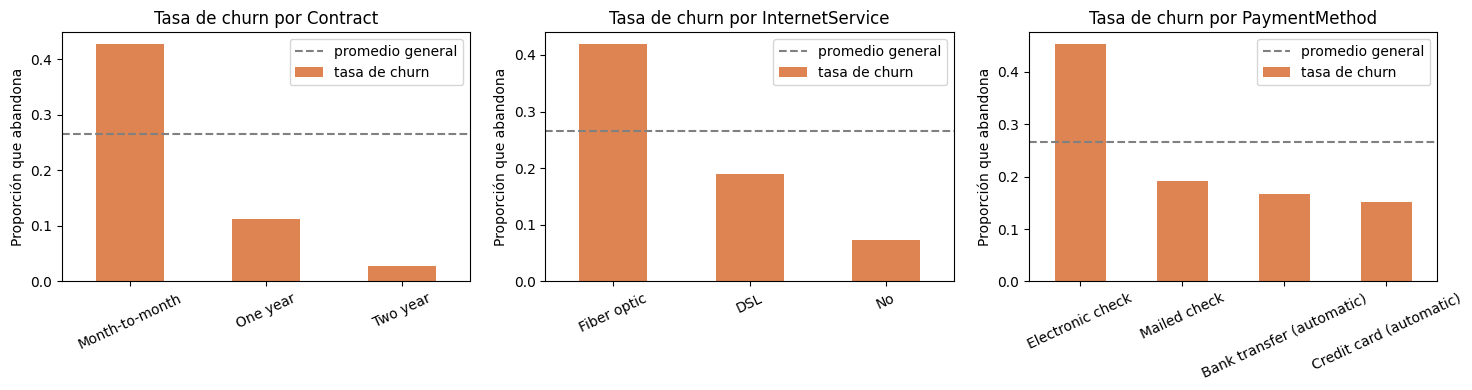

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    tasa = tasa_churn(col)
    tasa.plot(kind="bar", ax=ax, color="#DD8452", label="tasa de churn")
    ax.axhline(df["churn_num"].mean(), color="gray", linestyle="--", label="promedio general")
    ax.set_title(f"Tasa de churn por {col}")
    ax.set_ylabel("Proporción que abandona")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)
    ax.legend()
plt.tight_layout()
plt.savefig(RUTA_FIGURAS / "02_churn_por_categoria.png", dpi=120)
plt.show()

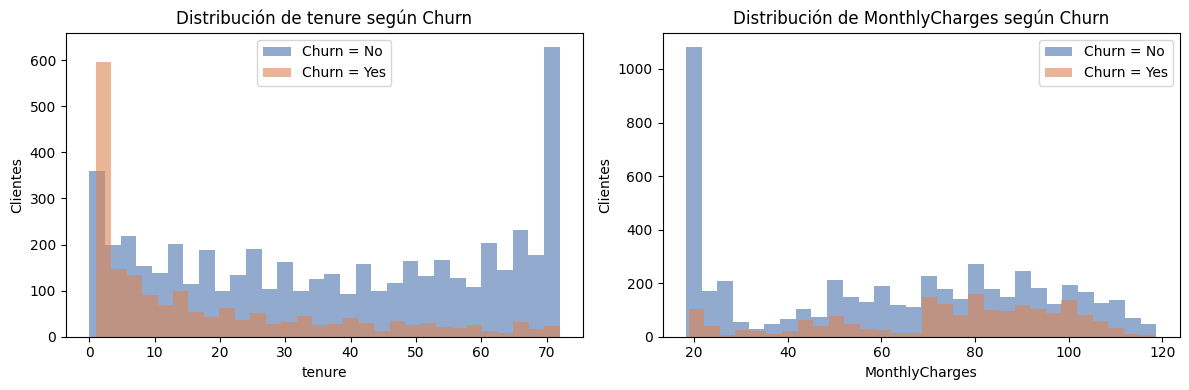

       tenure  MonthlyCharges
Churn                        
No       38.0          64.425
Yes      10.0          79.650


In [9]:
# Variables numéricas: antigüedad (tenure) y cargo mensual
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges"]):
    for valor, color in [("No", "#4C72B0"), ("Yes", "#DD8452")]:
        ax.hist(df.loc[df["Churn"] == valor, col], bins=30, alpha=0.6,
                label=f"Churn = {valor}", color=color)
    ax.set_title(f"Distribución de {col} según Churn")
    ax.set_xlabel(col)
    ax.set_ylabel("Clientes")
    ax.legend()
plt.tight_layout()
plt.savefig(RUTA_FIGURAS / "03_numericas_vs_churn.png", dpi=120)
plt.show()

print(df.groupby("Churn")[["tenure", "MonthlyCharges"]].median())

tenure
0-6      0.529
7-12     0.359
13-24    0.287
25-48    0.204
49-72    0.095
Name: churn_num, dtype: float64


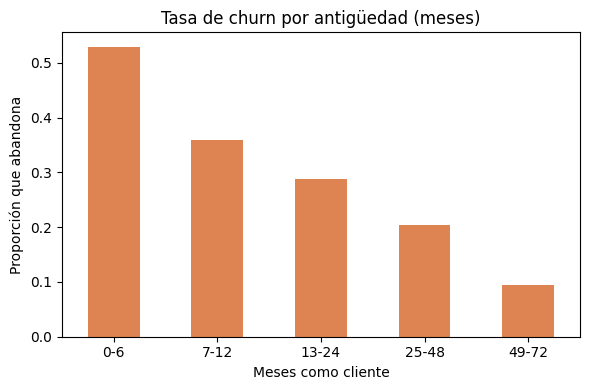

In [10]:
# Tasa de churn por rangos de antigüedad (meses)
rangos = pd.cut(df["tenure"], bins=[-1, 6, 12, 24, 48, 72],
                labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
tasa_tenure = df.groupby(rangos, observed=True)["churn_num"].mean().round(3)
print(tasa_tenure)

fig, ax = plt.subplots(figsize=(6, 4))
tasa_tenure.plot(kind="bar", ax=ax, color="#DD8452")
ax.set_title("Tasa de churn por antigüedad (meses)")
ax.set_xlabel("Meses como cliente")
ax.set_ylabel("Proporción que abandona")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(RUTA_FIGURAS / "04_churn_por_antiguedad.png", dpi=120)
plt.show()

## 4. Conclusiones de la Fase 1

**Calidad de datos**
- 7.043 clientes, 21 columnas, sin duplicados.
- `TotalCharges` viene como texto y tiene **11 valores vacíos** (clientes con `tenure = 0`) →
  en Fase 2 se convierte a número y se rellena con 0.
- `customerID` se elimina: es un identificador, no una característica.

**Desbalance**
- 26,5 % abandona / 73,5 % se queda → la accuracy engaña; priorizamos recall, costo y ROC-AUC.

**3 hallazgos clave sobre el abandono**
1. **Tipo de contrato** es el factor más fuerte: *mes a mes* abandona un **42,7 %**,
   contra 11,3 % (1 año) y **2,8 %** (2 años).
2. **Antigüedad:** los clientes nuevos son los más riesgosos. En los primeros 6 meses abandona
   el **52,9 %**; con más de 4 años, solo el 9,5 %. Mediana de antigüedad: 10 meses (se van) vs 38 (se quedan).
3. **Servicio y forma de pago:** fibra óptica (41,9 %), pago con *Electronic check* (45,3 %) y
   no tener soporte técnico ni seguridad online (~42 %) se asocian a mayor abandono.
   Los que se van pagan más por mes (mediana USD 79,7 vs 64,4).

**Variables que casi no diferencian:** `gender` (26,9 % vs 26,2 %) y `PhoneService`.

**Precaución:** estas son **asociaciones, no causas**. Por ejemplo, la fibra óptica puede no causar
el abandono; quizás esos clientes pagan más y comparan precios.

**Idea para la regla de referencia (sin ML):** "contactar a todos los clientes con contrato mes a mes".